In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("UrbanHub - Velos") \
    .config("spark.driver.memory", "4g") \
    .config("spark.jars.packages", "org.apache.hadoop:hadoop-aws:3.3.4,com.amazonaws:aws-java-sdk-bundle:1.12.262") \
    .config("spark.hadoop.fs.s3a.endpoint", "http://minio:9000") \
    .config("spark.hadoop.fs.s3a.access.key", "minioadmin") \
    .config("spark.hadoop.fs.s3a.secret.key", "minioadmin123") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled", "false") \
    .config("spark.sql.session.timeZone", "UTC") \
    .getOrCreate()

print("Spark pret :", spark.version)

Spark pret : 3.5.1


In [2]:
velos = spark.read.option("recursiveFileLookup", "true").json("s3a://bronze/velos/")

In [3]:
velos.printSchema()

root
 |-- bikes_available: long (nullable = true)
 |-- city: string (nullable = true)
 |-- collected_at: string (nullable = true)
 |-- ebikes: long (nullable = true)
 |-- free_slots: long (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- network_id: string (nullable = true)
 |-- renting: string (nullable = true)
 |-- slots: long (nullable = true)
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- timestamp: string (nullable = true)



In [4]:
velo = spark.read.option("recursiveFileLookup", "true").json("s3a://bronze/velos/")

print("Nombre de lignes :", velo.count())
velo.printSchema()
velo.show(5, truncate=False)

Nombre de lignes : 248276
root
 |-- bikes_available: long (nullable = true)
 |-- city: string (nullable = true)
 |-- collected_at: string (nullable = true)
 |-- ebikes: long (nullable = true)
 |-- free_slots: long (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- network_id: string (nullable = true)
 |-- renting: string (nullable = true)
 |-- slots: long (nullable = true)
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- timestamp: string (nullable = true)

+---------------+-----+---------------------------+------+----------+------------------+------------------+----------+-------+-----+--------------------------------+-------------------------+---------------------------------+
|bikes_available|city |collected_at               |ebikes|free_slots|latitude          |longitude         |network_id|renting|slots|station_id                      |station_name             |timestamp                 

In [5]:
from pyspark.sql import functions as F

paris = F.from_utc_timestamp("collected_at", "Europe/Paris")

silver = (velo
    # Regle 1 : texte -> vraie date/heure
    .withColumn("collected_at", F.to_timestamp("collected_at"))
    # Regle 2 : texte -> nombre
    .withColumn("renting", F.when(F.col("renting").isin("1", "true"), 1).otherwise(0))
    # Regle 3 : on enleve les lignes vides
    .filter(F.col("bikes_available").isNotNull() & F.col("free_slots").isNotNull())
    # Regle 4 : seulement les stations ouvertes
    .filter(F.col("renting") == 1)
    # Regle 5 : un seul enregistrement par station et par releve
    .dropDuplicates(["station_id", "collected_at"])
    # Regle 6 : heure de Paris (regles de l'equipe) + week-end
    .withColumn("date_local", F.to_date(paris))
    .withColumn("hour_local", F.hour(paris))
    .withColumn("is_weekend", F.dayofweek(paris).isin(1, 7))
    # Regle 7 : taux de remplissage (0 = vide, 1 = pleine)
    .withColumn("fill_rate", F.col("bikes_available") / (F.col("bikes_available") + F.col("free_slots")))
)

print("Avant :", velo.count(), "lignes")
print("Apres :", silver.count(), "lignes")
silver.select("city", "station_name", "collected_at", "hour_local", "bikes_available", "free_slots", "fill_rate").show(5)

Avant : 248276 lignes
Apres : 236011 lignes
+-----+------------------+--------------------+----------+---------------+----------+-------------------+
| city|      station_name|        collected_at|hour_local|bikes_available|free_slots|          fill_rate|
+-----+------------------+--------------------+----------+---------------+----------+-------------------+
|Paris|Argenson - Château|2026-10-21 13:24:...|        15|              4|        18|0.18181818181818182|
|Paris|Argenson - Château|2026-10-21 13:41:...|        15|              5|        17|0.22727272727272727|
|Paris|Argenson - Château|2026-10-21 14:22:...|        16|              3|        19|0.13636363636363635|
|Paris|Argenson - Château|2026-10-21 14:32:...|        16|              3|        19|0.13636363636363635|
|Paris|Argenson - Château|2026-10-21 14:37:...|        16|              3|        19|0.13636363636363635|
+-----+------------------+--------------------+----------+---------------+----------+-------------------+
on

In [6]:
avant = velo.groupBy("city").count().withColumnRenamed("count", "avant")
apres = silver.groupBy("city").count().withColumnRenamed("count", "apres")
avant.join(apres, "city", "left").orderBy("city").show()

# Que contient la colonne renting, ville par ville ?
velo.groupBy("city", "renting").count().orderBy("city").show(20)

+---------+------+------+
|     city| avant| apres|
+---------+------+------+
| Bordeaux| 19314| 18762|
|     Lyon| 39846| 39452|
|Marseille| 19836| 10614|
|    Paris|130376|128338|
| Toulouse| 38904| 38845|
+---------+------+------+

+---------+-------+------+
|     city|renting| count|
+---------+-------+------+
| Bordeaux|  false|   552|
| Bordeaux|   true| 18762|
|     Lyon|   true| 39452|
|     Lyon|  false|   394|
|Marseille|  false|  9222|
|Marseille|   true| 10614|
|    Paris|      0|  2038|
|    Paris|      1|128338|
| Toulouse|   true| 38845|
| Toulouse|  false|    59|
+---------+-------+------+



In [7]:
(silver.write
    .mode("overwrite")
    .partitionBy("city")
    .parquet("s3a://urbanhub/silver/velos/"))

print("Silver enregistre !")

Silver enregistre !


In [8]:
from pyspark.sql import Window

# La "fenetre" : chaque station separement, triee dans l'ordre du temps
fenetre = Window.partitionBy("station_id").orderBy("collected_at")

mouvements = (silver
    # nombre de velos au releve PRECEDENT de la meme station
    .withColumn("velos_avant", F.lag("bikes_available").over(fenetre))
    # heure du releve precedent
    .withColumn("heure_avant", F.lag("collected_at").over(fenetre))
    # changement = maintenant - avant
    .withColumn("changement", F.col("bikes_available") - F.col("velos_avant"))
    # on garde seulement 2 releves proches (moins de 10 min d'ecart)
    .filter((F.unix_timestamp("collected_at") - F.unix_timestamp("heure_avant")) <= 600)
    .withColumn("departs",  F.when(F.col("changement") < 0, -F.col("changement")).otherwise(0))
    .withColumn("arrivees", F.when(F.col("changement") > 0,  F.col("changement")).otherwise(0))
)

mouvements.select("city", "station_name", "collected_at", "velos_avant",
                  "bikes_available", "changement", "departs", "arrivees").show(10)

+-----+------------------+--------------------+-----------+---------------+----------+-------+--------+
| city|      station_name|        collected_at|velos_avant|bikes_available|changement|departs|arrivees|
+-----+------------------+--------------------+-----------+---------------+----------+-------+--------+
|Paris|Argenson - Château|2026-10-21 13:07:...|          4|              4|         0|      0|       0|
|Paris|Argenson - Château|2026-10-21 13:09:...|          4|              4|         0|      0|       0|
|Paris|Argenson - Château|2026-10-21 13:12:...|          4|              4|         0|      0|       0|
|Paris|Argenson - Château|2026-10-21 13:14:...|          4|              4|         0|      0|       0|
|Paris|Argenson - Château|2026-10-21 13:17:...|          4|              4|         0|      0|       0|
|Paris|Argenson - Château|2026-10-21 13:19:...|          4|              4|         0|      0|       0|
|Paris|Argenson - Château|2026-10-21 13:22:...|          4|     

In [9]:
mouvements.groupBy("city", "hour_local").agg(F.sum("departs"), F.sum("arrivees")).orderBy("city", "hour_local").show(50)

+---------+----------+------------+-------------+
|     city|hour_local|sum(departs)|sum(arrivees)|
+---------+----------+------------+-------------+
| Bordeaux|         9|         266|          310|
| Bordeaux|        10|          82|           89|
| Bordeaux|        11|           9|            8|
| Bordeaux|        15|         218|          218|
| Bordeaux|        16|         338|          275|
| Bordeaux|        17|         369|          316|
|     Lyon|         9|        1434|         2158|
|     Lyon|        10|         471|          632|
|     Lyon|        11|          79|           63|
|     Lyon|        15|        1209|         1019|
|     Lyon|        16|        1781|         1497|
|     Lyon|        17|        1655|         1075|
|Marseille|         9|           0|            0|
|Marseille|        10|           0|            0|
|Marseille|        11|           0|            0|
|Marseille|        15|           0|            0|
|Marseille|        16|           0|            0|


In [10]:
GOLD = "s3a://urbanhub/gold"
RELEVE_H = 150 / 3600          # un releve = 2 min 30 = 0,0417 heure

# ---------- Fiche de chaque station (capacite, remplissage, % du temps vide / pleine)
stations = (silver
    .withColumn("capacite", F.col("bikes_available") + F.col("free_slots"))
    .groupBy("city", "station_id")
    .agg(F.first("station_name").alias("station_name"),
         F.first("latitude").alias("latitude"), F.first("longitude").alias("longitude"),
         F.max("capacite").alias("capacite"),
         F.avg("bikes_available").alias("velos_moy"),
         F.avg("fill_rate").alias("remplissage_moy"),
         F.avg((F.col("bikes_available") == 0).cast("int")).alias("part_temps_vide"),
         F.avg((F.col("free_slots") == 0).cast("int")).alias("part_temps_pleine"))
    .filter(F.col("capacite") > 0))

# ---------- Q1 : stations les plus utilisees (mouvements par heure et par borne)
activite = mouvements.groupBy("station_id").agg(
    F.sum(F.col("departs") + F.col("arrivees")).alias("mouvements"),
    F.count("*").alias("nb_intervalles"))
q1 = (stations.join(activite, "station_id")
    .withColumn("mouvements_par_heure", F.col("mouvements") / (F.col("nb_intervalles") * RELEVE_H))
    .withColumn("taux_utilisation", F.col("mouvements_par_heure") / F.col("capacite")))

# ---------- Q2 : zones (carres d'environ 1 km) ou il manque des velos
q2 = (silver
    .withColumn("zone_lat", F.round("latitude", 2)).withColumn("zone_lon", F.round("longitude", 2))
    .groupBy("city", "zone_lat", "zone_lon", "collected_at")
    .agg(F.sum("bikes_available").alias("velos"),
         F.sum(F.col("bikes_available") + F.col("free_slots")).alias("places"),
         F.countDistinct("station_id").alias("nb_stations"))
    .withColumn("remplissage", F.col("velos") / F.col("places"))
    .groupBy("city", "zone_lat", "zone_lon")
    .agg(F.avg("remplissage").alias("remplissage_moy"),
         F.avg((F.col("remplissage") < 0.10).cast("int")).alias("part_temps_penurie"),
         F.max("nb_stations").alias("nb_stations"))
    .withColumn("offre_insuffisante", F.col("part_temps_penurie") >= 0.25))

# ---------- Q3 : pics d'utilisation (mouvements par heure, semaine / week-end)
q3 = (mouvements
    .withColumn("type_jour", F.when(F.col("is_weekend"), "week-end").otherwise("semaine"))
    .groupBy("city", "type_jour", "hour_local")
    .agg((F.sum(F.col("departs") + F.col("arrivees"))
          / (F.countDistinct("collected_at") * RELEVE_H)).alias("mouvements_par_heure")))

# ---------- Q4 : desequilibres geographiques (centre-ville / peripherie, selon le moment)
centres = spark.createDataFrame([
    ("Paris", 48.8566, 2.3522), ("Lyon", 45.7640, 4.8357), ("Marseille", 43.2965, 5.3698),
    ("Toulouse", 43.6047, 1.4442), ("Bordeaux", 44.8378, -0.5792)], ["city", "c_lat", "c_lon"])
dlat = F.radians(F.col("latitude") - F.col("c_lat")); dlon = F.radians(F.col("longitude") - F.col("c_lon"))
dist = 2 * 6371 * F.asin(F.sqrt(F.sin(dlat / 2) ** 2 + F.cos(F.radians("c_lat")) * F.cos(F.radians("latitude")) * F.sin(dlon / 2) ** 2))
zones_dist = (stations.join(centres, "city").withColumn("distance_km", dist)
    .withColumn("zone", F.when(F.col("distance_km") < 2, "1. centre (< 2 km)")
                         .when(F.col("distance_km") < 5, "2. 2 a 5 km").otherwise("3. > 5 km"))
    .select("station_id", "distance_km", "zone"))
q4 = (silver.join(zones_dist, "station_id")
    .withColumn("moment", F.when(F.col("hour_local").between(6, 9), "1. matin (6-10h)")
                           .when(F.col("hour_local").between(10, 15), "2. journee (10-16h)")
                           .when(F.col("hour_local").between(16, 20), "3. soir (16-21h)")
                           .otherwise("4. nuit"))
    .groupBy("city", "zone", "moment").agg(F.avg("fill_rate").alias("remplissage_moy"),
                                           F.countDistinct("station_id").alias("nb_stations")))

# ---------- Q5 : stations critiques (vides ou pleines plus de 25 % du temps)
q5 = (stations
    .withColumn("probleme", F.when(F.col("part_temps_vide") >= 0.25, "a reapprovisionner")
                             .when(F.col("part_temps_pleine") >= 0.25, "a delester"))
    .filter(F.col("probleme").isNotNull())
    .withColumn("priorite", F.greatest("part_temps_vide", "part_temps_pleine"))
    .withColumn("velos_a_deplacer", F.round(F.col("capacite") * 0.5 - F.col("velos_moy")).cast("int")))

# ---------- Table pour la Partie 4 : une ligne par ville et par heure (meme grain que meteo / pollution)
velos_horaire = (mouvements
    .withColumn("timestamp", F.date_trunc("hour", "collected_at"))
    .groupBy("city", "timestamp", "date_local", "hour_local")
    .agg((F.sum(F.col("departs") + F.col("arrivees"))
          / (F.countDistinct("collected_at") * RELEVE_H)).alias("mouvements_par_heure"),
         F.avg("fill_rate").alias("remplissage_moy")))

# ---------- Enregistrement dans la couche Gold
tables = {"velos_q1_utilisation_stations": q1, "velos_q2_zones_offre": q2,
          "velos_q3_profil_horaire": q3, "velos_q4_desequilibres": q4,
          "velos_q5_stations_critiques": q5, "velos_horaire_ville": velos_horaire}
for nom, t in tables.items():
    t.write.mode("overwrite").parquet(f"{GOLD}/{nom}/")
    print("Gold enregistre :", nom)

Gold enregistre : velos_q1_utilisation_stations
Gold enregistre : velos_q2_zones_offre
Gold enregistre : velos_q3_profil_horaire
Gold enregistre : velos_q4_desequilibres
Gold enregistre : velos_q5_stations_critiques
Gold enregistre : velos_horaire_ville


In [13]:
# Corrections : Marseille exclu (API sans mise a jour) et petites stations (< 5 bornes) ecartees
q1 = q1.filter(F.col("capacite") >= 5)
q2 = q2.filter(F.col("city") != "Marseille")
q4 = q4.filter(F.col("city") != "Marseille")
q5 = q5.filter(F.col("city") != "Marseille")

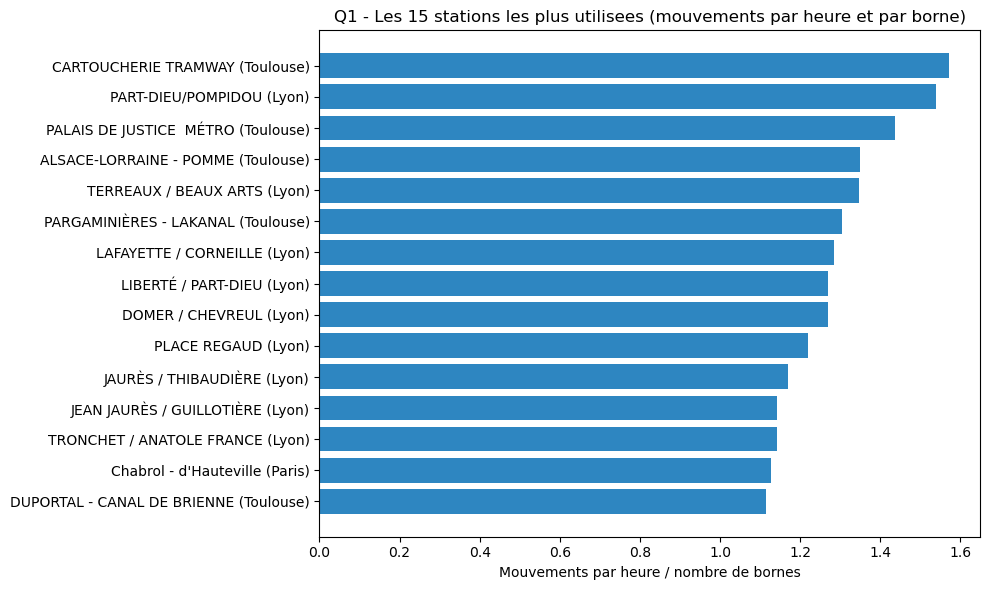

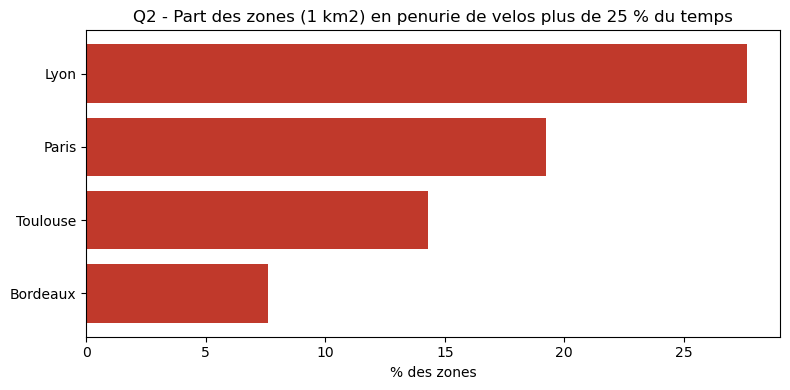

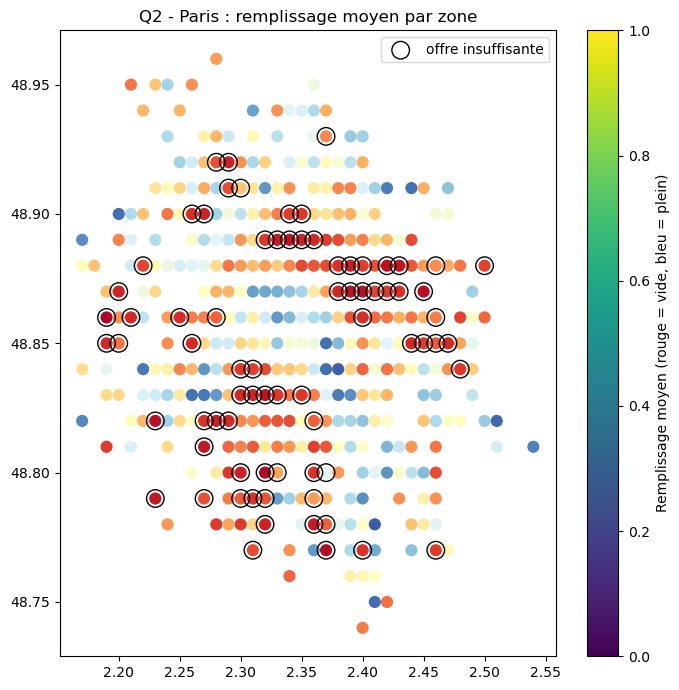

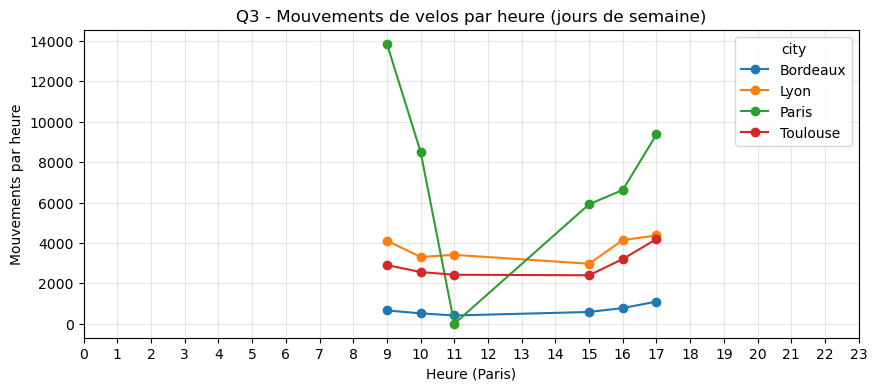

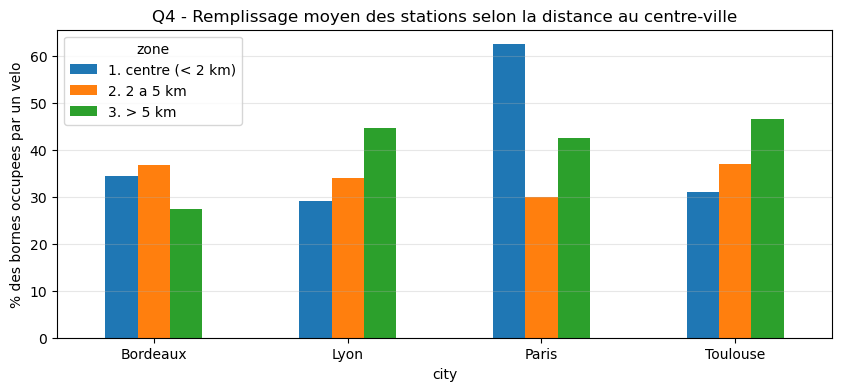

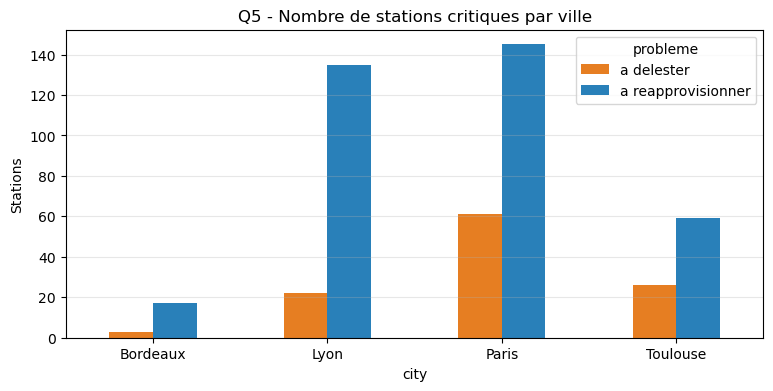

Q1 - Top 5 stations :
            station_name     city  capacite  mouvements_par_heure  taux_utilisation
    CARTOUCHERIE TRAMWAY Toulouse        10                 15.70              1.57
      PART-DIEU/POMPIDOU     Lyon        40                 61.60              1.54
PALAIS DE JUSTICE  MÉTRO Toulouse        13                 18.67              1.44
 ALSACE-LORRAINE - POMME Toulouse        18                 24.30              1.35
   TERREAUX / BEAUX ARTS     Lyon        10                 13.46              1.35

Q2 - % de zones en penurie par ville :
city
Bordeaux     7.6
Toulouse    14.3
Paris       19.2
Lyon        27.6

Q3 - Heure de pointe par ville :
city
Bordeaux    17
Lyon        17
Paris        9
Toulouse    17

Q4 - Remplissage (%) :
zone      1. centre (< 2 km)  2. 2 a 5 km  3. > 5 km
city                                                
Bordeaux                34.4         36.7       27.5
Lyon                    29.1         33.9       44.6
Paris                   62

In [14]:
import os
import matplotlib.pyplot as plt
FIG = "/home/jovyan/work/data/figures"
os.makedirs(FIG, exist_ok=True)
villes_actives = ["Paris", "Lyon", "Toulouse", "Bordeaux"]   # Marseille : aucun mouvement dans l'API

# ---------- Q1 : top 15 des stations les plus utilisees
p1 = (q1.filter(F.col("city").isin(villes_actives)).orderBy(F.desc("taux_utilisation")).limit(15).toPandas())
p1["nom"] = p1["station_name"].str.slice(0, 30) + " (" + p1["city"] + ")"
plt.figure(figsize=(10, 6))
plt.barh(p1["nom"][::-1], p1["taux_utilisation"][::-1], color="#2e86c1")
plt.title("Q1 - Les 15 stations les plus utilisees (mouvements par heure et par borne)")
plt.xlabel("Mouvements par heure / nombre de bornes"); plt.tight_layout()
plt.savefig(f"{FIG}/velos_q1_stations.png", dpi=120); plt.show()

# ---------- Q2 : zones ou l'offre est insuffisante
p2 = q2.toPandas()
part = p2.groupby("city")["offre_insuffisante"].mean().sort_values() * 100
plt.figure(figsize=(8, 4)); plt.barh(part.index, part.values, color="#c0392b")
plt.title("Q2 - Part des zones (1 km2) en penurie de velos plus de 25 % du temps")
plt.xlabel("% des zones"); plt.tight_layout()
plt.savefig(f"{FIG}/velos_q2_zones_ville.png", dpi=120); plt.show()
paris = p2[p2["city"] == "Paris"]
plt.figure(figsize=(7, 7))
plt.scatter(paris["zone_lon"], paris["zone_lat"], c=paris["remplissage_moy"], cmap="RdYlBu", s=60, vmin=0, vmax=1)
manque = paris[paris["offre_insuffisante"]]
plt.scatter(manque["zone_lon"], manque["zone_lat"], s=160, facecolors="none", edgecolors="black", label="offre insuffisante")
plt.colorbar(label="Remplissage moyen (rouge = vide, bleu = plein)")
plt.title("Q2 - Paris : remplissage moyen par zone"); plt.legend(); plt.tight_layout()
plt.savefig(f"{FIG}/velos_q2_carte_paris.png", dpi=120); plt.show()

# ---------- Q3 : profil horaire (semaine)
p3 = (q3.filter(F.col("city").isin(villes_actives) & (F.col("type_jour") == "semaine")).toPandas()
      .pivot(index="hour_local", columns="city", values="mouvements_par_heure").sort_index())
p3.plot(figsize=(10, 4), marker="o")
plt.title("Q3 - Mouvements de velos par heure (jours de semaine)")
plt.xlabel("Heure (Paris)"); plt.ylabel("Mouvements par heure"); plt.xticks(range(24)); plt.grid(alpha=0.3)
plt.savefig(f"{FIG}/velos_q3_profil_horaire.png", dpi=120, bbox_inches="tight"); plt.show()

# ---------- Q4 : remplissage selon la distance au centre
p4 = (q4.groupBy("city", "zone").agg(F.avg("remplissage_moy").alias("r")).toPandas()
      .pivot(index="city", columns="zone", values="r") * 100)
p4.plot(kind="bar", figsize=(10, 4), rot=0)
plt.title("Q4 - Remplissage moyen des stations selon la distance au centre-ville")
plt.ylabel("% des bornes occupees par un velo"); plt.grid(axis="y", alpha=0.3)
plt.savefig(f"{FIG}/velos_q4_distance_centre.png", dpi=120, bbox_inches="tight"); plt.show()

# ---------- Q5 : stations critiques
p5 = q5.toPandas()
compte = p5.groupby(["city", "probleme"]).size().unstack(fill_value=0)
compte.plot(kind="bar", figsize=(9, 4), rot=0, color=["#e67e22", "#2980b9"])
plt.title("Q5 - Nombre de stations critiques par ville"); plt.ylabel("Stations"); plt.grid(axis="y", alpha=0.3)
plt.savefig(f"{FIG}/velos_q5_stations_critiques.png", dpi=120, bbox_inches="tight"); plt.show()

# ---------- Chiffres cles
print("Q1 - Top 5 stations :")
print(p1[["station_name", "city", "capacite", "mouvements_par_heure", "taux_utilisation"]].head(5).round(2).to_string(index=False))
print("\nQ2 - % de zones en penurie par ville :"); print(part.round(1).to_string())
print("\nQ3 - Heure de pointe par ville :"); print(p3.idxmax().to_string())
print("\nQ4 - Remplissage (%) :"); print(p4.round(1).to_string())
print("\nQ5 - Stations critiques :"); print(compte.to_string())
print("\nTop 5 priorites :")
print(p5.sort_values("priorite", ascending=False)[["station_name", "city", "probleme", "priorite", "velos_a_deplacer"]].head(5).round(2).to_string(index=False))